In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/kamp_2026/data/okm_augumented_2021.csv", encoding="utf-8-sig")
df.describe()

,날짜,시간,15분,30분,45분,60분,평균,생산량,기온,풍속,습도,강수량,전기요금(계절),day,d,m,공장인원,인건비
count,6.168000e+03,6168.000000,6168.000000,6168.000000,6168.000000,6168.000000,6168.000000,6168.000000,6168.000000,6165.000000,6168.000000,6167.000000,6168.000000,6168.000000,6168.000000,6168.000000,6151.000000,6168.000000
mean,2.021049e+07,12.428016,90.410182,92.695363,95.106355,95.037938,93.424125,467.344682,15.906064,2.063633,70.098735,2.244252,162.757198,4.003891,15.256809,4.770428,0.901336,1.313959
std,2.447756e+02,12.847309,55.349403,57.942122,59.285709,59.347554,57.355938,857.571815,9.160356,1.164118,22.996164,9.613491,30.820855,2.006957,8.799601,2.452431,1.985511,0.241700
min,2.021010e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-12.000000,0.000000,8.000000,0.000000,109.800000,1.000000,1.000000,1.000000,0.000000,1.000000
25%,2.021031e+07,6.000000,23.000000,23.000000,23.000000,23.000000,23.000000,0.000000,9.600000,1.200000,53.000000,0.000000,167.200000,2.000000,8.000000,3.000000,0.000000,1.000000
50%,2.021051e+07,12.000000,101.000000,104.000000,105.000000,107.000000,104.000000,45.000000,17.400000,1.900000,74.000000,0.000000,167.200000,4.000000,15.000000,5.000000,0.112971,1.500000
75%,2.021071e+07,18.000000,133.000000,143.000000,149.000000,149.000000,144.000000,637.250000,23.300000,2.800000,91.000000,0.100000,191.600000,6.000000,23.000000,7.000000,1.162285,1.500000
max,2.021091e+07,188.000000,207.000000,222.000000,218.000000,214.000000,208.000000,9830.000000,33.400000,7.600000,98.000000,122.400000,191.600000,7.000000,31.000000,9.000000,48.386364,1.500000


In [3]:
print(sorted(df["시간"].unique().tolist()))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 70, 74, 86, 89, 90, 97, 98, 100, 107, 108, 110, 111, 112, 113, 115, 118, 120, 121, 124, 125, 133, 134, 136, 147, 148, 155, 159, 162, 165, 171, 172, 173, 178, 183, 184, 188]


In [4]:
hour_counts = df["시간"].value_counts().sort_index()
hour_distribution = hour_counts.rename("개수").to_frame()
hour_distribution["비율(%)"] = (hour_counts / len(df) * 100).round(2)
print(hour_distribution.to_string())

      개수  비율(%)
시간             
0    255   4.13
1    255   4.13
2    255   4.13
3    255   4.13
4    255   4.13
5    255   4.13
6    255   4.13
7    255   4.13
8    255   4.13
9    255   4.13
10   255   4.13
11   255   4.13
12   255   4.13
13   255   4.13
14   255   4.13
15   255   4.13
16   255   4.13
17   255   4.13
18   255   4.13
19   255   4.13
20   255   4.13
21   255   4.13
22   255   4.13
23   255   4.13
70     1   0.02
74     1   0.02
86     1   0.02
89     2   0.03
90     1   0.02
97     1   0.02
98     1   0.02
100    1   0.02
107    1   0.02
108    1   0.02
110    2   0.03
111    1   0.02
112    1   0.02
113    1   0.02
115    3   0.05
118    1   0.02
120    3   0.05
121    2   0.03
124    1   0.02
125    1   0.02
133    1   0.02
134    1   0.02
136    1   0.02
147    1   0.02
148    2   0.03
155    1   0.02
159    3   0.05
162    1   0.02
165    1   0.02
171    1   0.02
172    3   0.05
173    1   0.02
178    1   0.02
183    1   0.02
184    1   0.02
188    1   0.02


In [5]:
from html import escape
from IPython.display import HTML, display

value_distributions = {}
for col in df.columns:
    counts = df[col].value_counts(dropna=False).sort_index()
    table = counts.rename_axis("값").reset_index(name="개수")
    table["비율(%)"] = (table["개수"] / len(df) * 100).round(2)
    value_distributions[col] = table
    display(HTML(
        f"<details><summary><b>{escape(col)}</b> — 고유값 {df[col].nunique():,}개, 결측 {df[col].isna().sum():,}개</summary>"
        '<div style="max-height:400px; overflow:auto">'
        + table.to_html(index=False, na_rep="결측", float_format=lambda x: format(x, ".12g"))
        + "</div></details>"
    ))


값,개수,비율(%)
20210101,24,0.39
20210102,24,0.39
20210103,24,0.39
20210104,24,0.39
20210105,24,0.39
20210106,24,0.39
20210107,24,0.39
20210108,24,0.39
20210109,24,0.39
20210110,24,0.39


값,개수,비율(%)
0,255,4.13
1,255,4.13
2,255,4.13
3,255,4.13
4,255,4.13
5,255,4.13
6,255,4.13
7,255,4.13
8,255,4.13
9,255,4.13


값,개수,비율(%)
0,19,0.31
19,18,0.29
20,186,3.02
21,562,9.11
22,547,8.87
23,279,4.52
24,200,3.24
25,88,1.43
26,93,1.51
27,46,0.75


값,개수,비율(%)
0,19,0.31
19,29,0.47
20,199,3.23
21,531,8.61
22,526,8.53
23,289,4.69
24,175,2.84
25,106,1.72
26,96,1.56
27,57,0.92


값,개수,비율(%)
0,18,0.29
19,14,0.23
20,209,3.39
21,550,8.92
22,586,9.5
23,276,4.47
24,155,2.51
25,58,0.94
26,99,1.61
27,45,0.73


...

값,개수,비율(%)
1,888,14.4
2,888,14.4
3,864,14.01
4,864,14.01
5,888,14.4
6,888,14.4
7,888,14.4


값,개수,비율(%)
1,216,3.5
2,216,3.5
3,216,3.5
4,216,3.5
5,216,3.5
6,216,3.5
7,216,3.5
8,216,3.5
9,216,3.5
10,216,3.5


값,개수,비율(%)
1,744,12.06
2,672,10.89
3,744,12.06
4,720,11.67
5,744,12.06
6,720,11.67
7,744,12.06
8,744,12.06
9,336,5.45


값,개수,비율(%)
0,2640,42.8
0.001886792,1,0.02
0.001908397,1,0.02
0.001956947,1,0.02
0.001960784,1,0.02
0.002070393,1,0.02
0.002222222,1,0.02
0.002277904,1,0.02
0.002298851,1,0.02
0.002358491,2,0.03


값,개수,비율(%)
1,2295,37.21
1.5,3873,62.79


In [6]:
# 결측 포함 행
print(df[df.isna().any(axis=1)])

            날짜  시간  15분  30분  45분  60분   평균  생산량    기온   풍속  습도   강수량  \
552   20210124   0   73   70   69   69   70    0   9.8  3.9  66   NaN   
3625  20210601   1   89   94  106  105   99   80  15.3  NaN  98   0.0   
3626  20210601   2  102   99  107  106  104  135  15.2  NaN  96   0.0   
4436  20210704  20   22   23   22   22   22    0  25.4  NaN  81  24.7   
5754  20210828  18    0    0    0    0    0    0  25.9  0.7  81   0.2   
5755  20210828  19    0    0    0    0    0    0  25.4  0.3  88   0.2   
5756  20210828  20    0    0    0    0    0    0  24.8  1.2  90   0.2   
5757  20210828  21    0    0    0    0    0    0  24.3  1.2  91   0.2   
5758  20210828  22    0    0    0    0    0    0  24.4  1.5  89   0.2   
5759  20210828  23    0    0    0    0    0    0  24.3  1.1  83   0.2   
5760  20210829   0    0    0    0    0    0    0  23.9  0.8  83   0.0   
5761  20210829   1    0    0    0    0    0    0  23.7  0.6  84   0.0   
5762  20210829   2    0    0    0    0    0    0  2

In [7]:
power_cols = ["15분", "30분", "45분", "60분"]
dates = pd.to_datetime(df["날짜"].astype(str), format="%Y%m%d")

valid = (
    df["시간"].between(0, 23)                                   # 손상 시간값(7/13·7/15) 제외
    & (df["평균"] == (df[power_cols].mean(axis=1) + 0.5) // 1)  # 평균 = 4칸 평균(반올림)
    & (df[power_cols + ["생산량", "풍속", "강수량"]] >= 0).all(axis=1)
    & df["습도"].between(0, 100)
    & (df["m"] == dates.dt.month)
    & (df["d"] == dates.dt.day)
    & (df["day"] == dates.dt.dayofweek + 1)
)
df_clean = df[valid].dropna().reset_index(drop=True)
print(f"{len(df)} → {len(df_clean)}행 (제거 {len(df) - len(df_clean)}행)")
df_clean.describe()

6168 → 6099행 (제거 69행)


,날짜,시간,15분,30분,45분,60분,평균,생산량,기온,풍속,습도,강수량,전기요금(계절),day,d,m,공장인원,인건비
count,6.099000e+03,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000,6099.000000
mean,2.021049e+07,11.506640,90.345303,92.615347,95.037219,95.005247,93.363338,472.596655,15.791179,2.071897,69.923758,2.265027,162.444302,4.004099,15.234465,4.743728,0.908934,1.312018
std,2.446427e+02,6.917099,55.237631,57.830119,59.180797,59.285222,57.254570,860.976716,9.139552,1.165047,23.043920,9.659823,30.835679,2.008301,8.814073,2.451512,1.992239,0.242205
min,2.021010e+07,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,0.000000,-12.000000,0.000000,8.000000,0.000000,109.800000,1.000000,1.000000,1.000000,0.000000,1.000000
25%,2.021030e+07,6.000000,23.000000,23.000000,23.000000,23.000000,23.000000,0.000000,9.500000,1.200000,53.000000,0.000000,167.200000,2.000000,8.000000,3.000000,0.000000,1.000000
50%,2.021051e+07,12.000000,101.000000,104.000000,105.000000,107.000000,104.000000,50.000000,17.300000,1.900000,74.000000,0.000000,167.200000,4.000000,15.000000,5.000000,0.121622,1.500000
75%,2.021071e+07,17.000000,133.000000,142.000000,148.000000,149.000000,144.000000,654.500000,23.200000,2.900000,91.000000,0.100000,191.600000,6.000000,23.000000,7.000000,1.174415,1.500000
max,2.021091e+07,23.000000,207.000000,222.000000,218.000000,214.000000,208.000000,9830.000000,33.400000,7.600000,98.000000,122.400000,191.600000,7.000000,31.000000,9.000000,48.386364,1.500000


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 56.2 MB/s eta 0:00:0000:0100:01


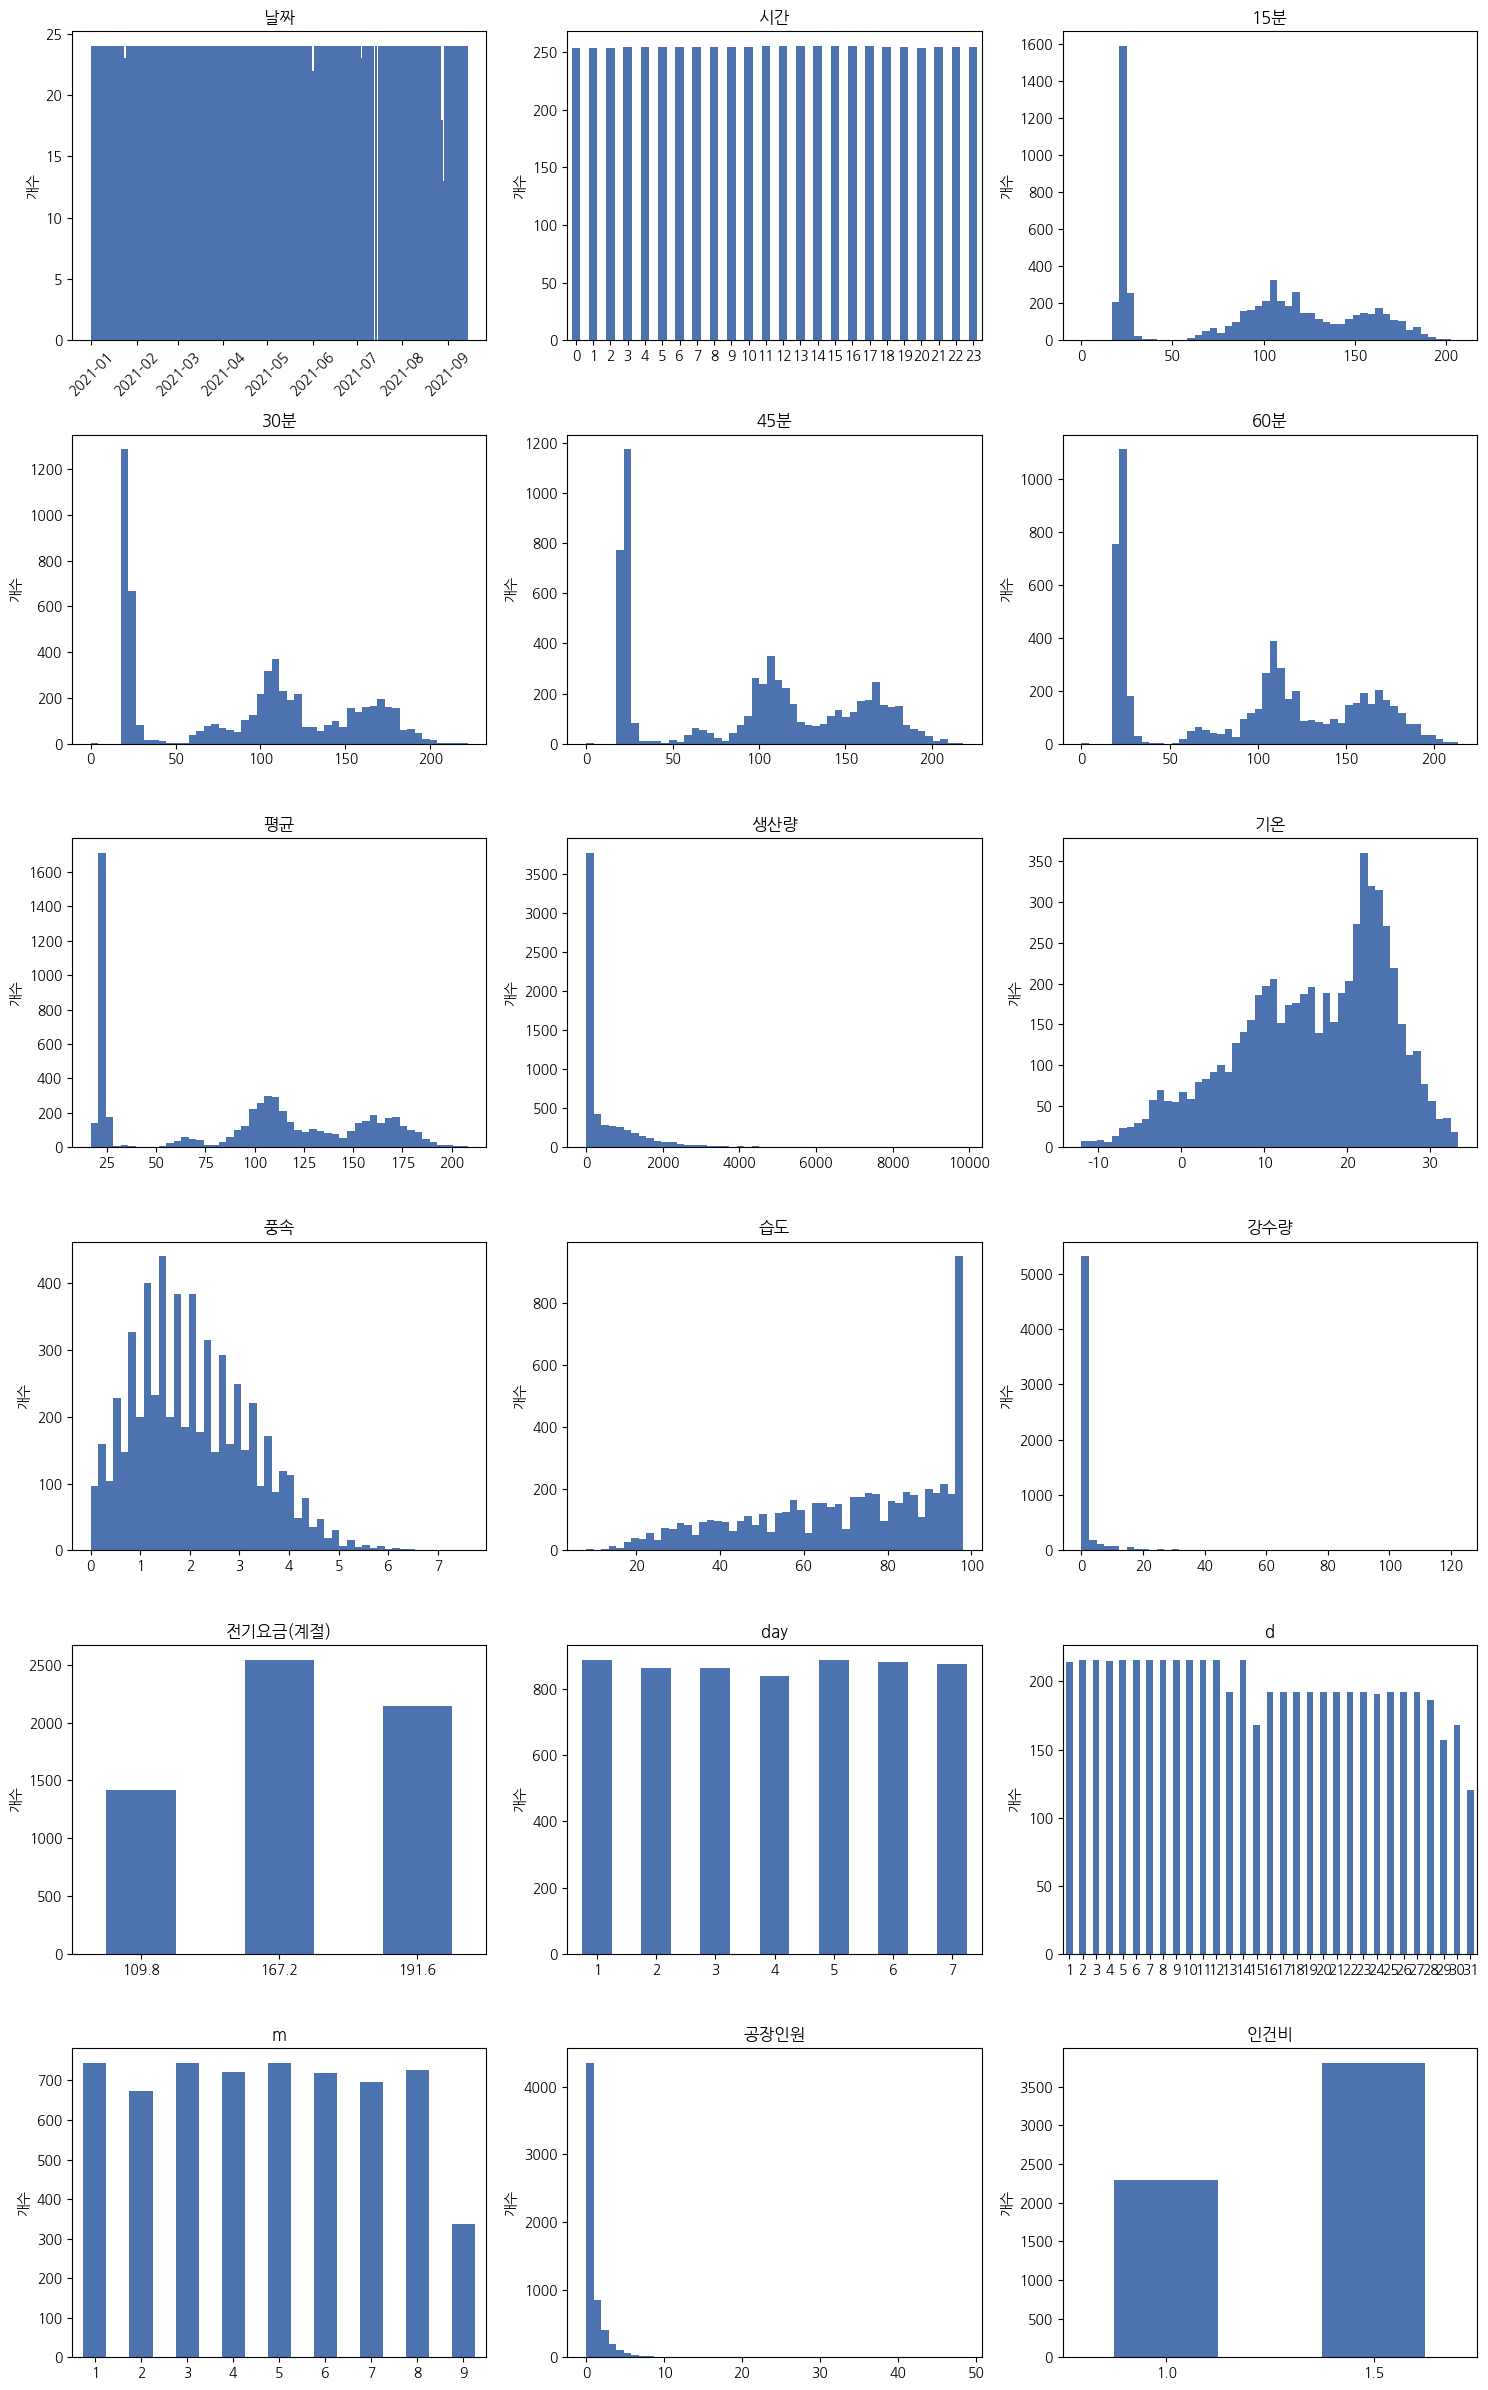

In [8]:
%pip install -q koreanize-matplotlib
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 폰트

discrete_cols = ["시간", "전기요금(계절)", "day", "d", "m", "인건비"]
color = "#4C72B0"

fig, axes = plt.subplots(6, 3, figsize=(15, 24))
for ax, col in zip(axes.flat, df_clean.columns):
    s = df_clean[col]
    if col == "날짜":
        counts = pd.to_datetime(s.astype(str), format="%Y%m%d").value_counts()
        counts = counts.reindex(pd.date_range(counts.index.min(), counts.index.max()), fill_value=0)  # 누락일 0
        ax.bar(counts.index, counts.values, width=1, color=color)  # 날짜별 행 수 (정상 24)
        ax.tick_params(axis="x", rotation=45)
    elif col in discrete_cols:
        s.value_counts().sort_index().plot.bar(ax=ax, color=color, rot=0)
    else:
        ax.hist(s, bins=50, color=color)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("개수")
fig.tight_layout()
plt.show()

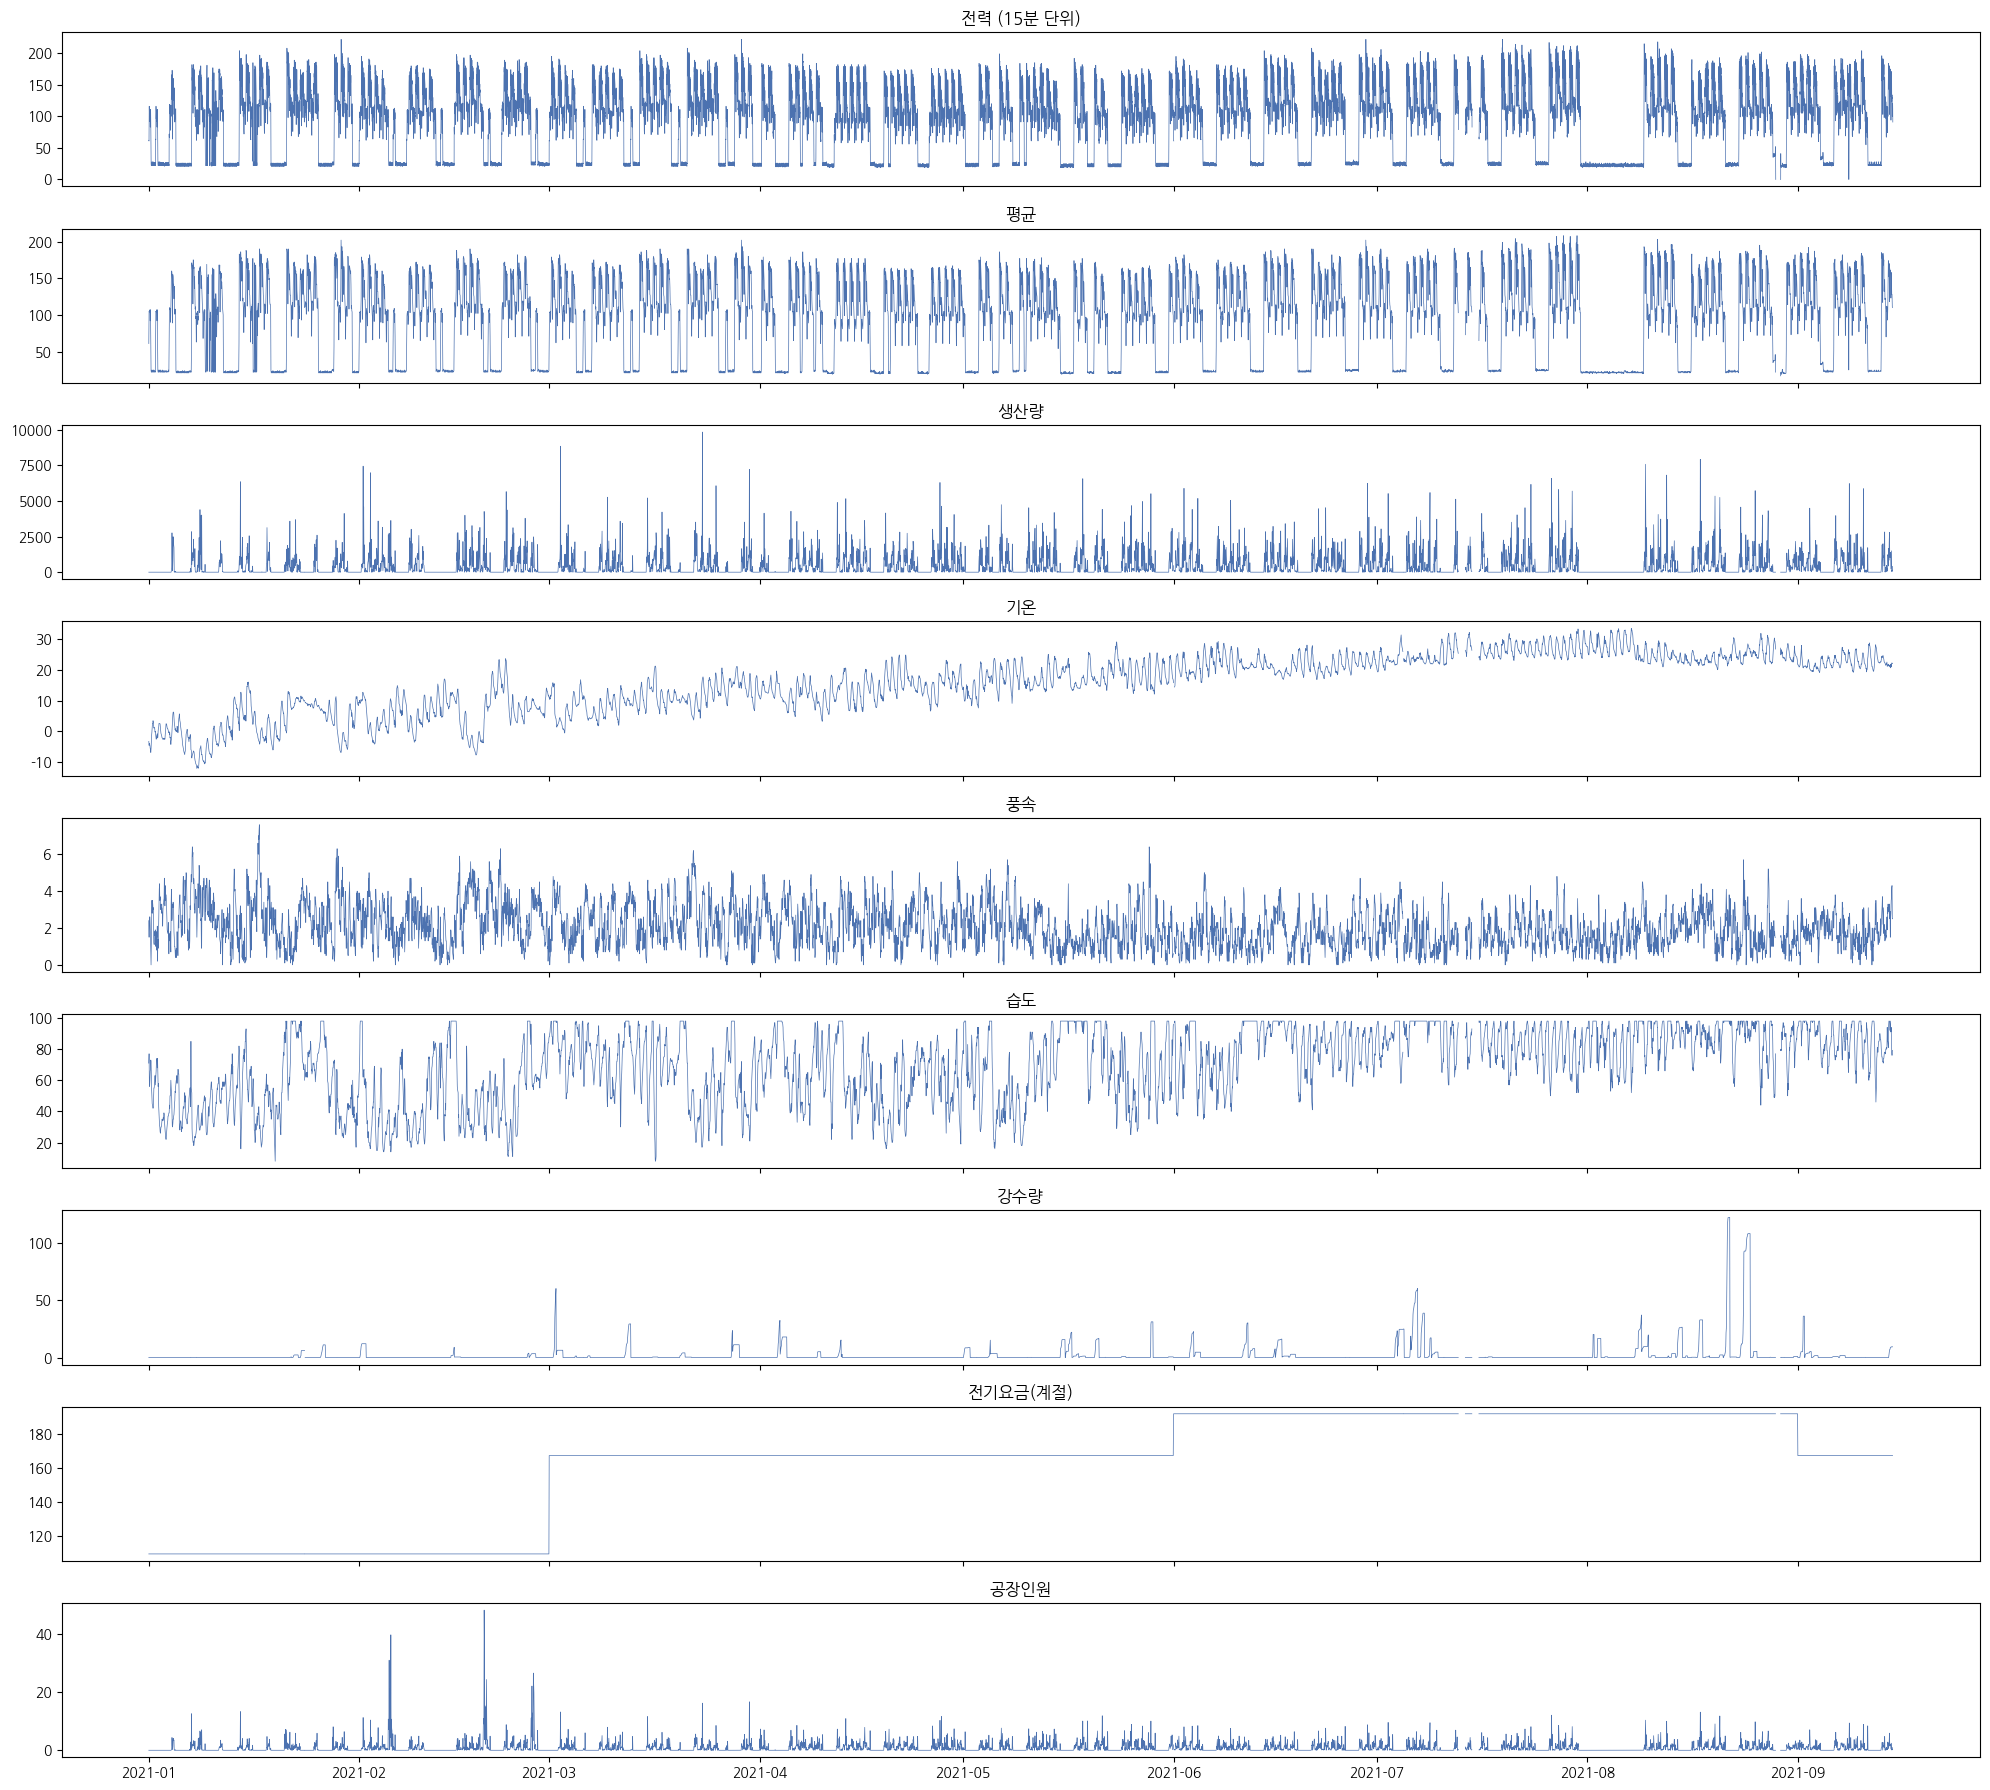

In [9]:
ts = pd.to_datetime(df_clean["날짜"].astype(str), format="%Y%m%d") + pd.to_timedelta(df_clean["시간"], unit="h")
x = df_clean.drop(columns=["날짜", "시간", "day", "d", "m", "인건비"]).set_index(ts)  # 날짜·시간 파생 컬럼 제외

# 15분 구간 시계열: 15분→HH:00, 30분→HH:15, 45분→HH:30, 60분→HH:45 (구간 시작 시각)
offsets = {"15분": 0, "30분": 15, "45분": 30, "60분": 45}
p = x[power_cols].rename(columns=offsets).stack()
power15 = pd.Series(p.values, index=p.index.get_level_values(0) + pd.to_timedelta(p.index.get_level_values(1), unit="min"))
power15 = power15.asfreq("15min")  # 제거 시간 = 결측

others = x.drop(columns=power_cols).asfreq("h")
fig, axes = plt.subplots(1 + others.shape[1], 1, figsize=(20, 2 * (1 + others.shape[1])), sharex=True)
axes[0].plot(power15.index, power15.values, color="#4C72B0", lw=0.5)
axes[0].set_title("전력 (15분 단위)")
for ax, col in zip(axes[1:], others.columns):
    ax.plot(others.index, others[col], color="#4C72B0", lw=0.5)
    ax.set_title(col)
plt.tight_layout()
plt.show()